In [1]:
# Configuration: edit this JSON file, then restart the kernel and Run All.
from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "functions.py").is_file() and (p / "applications/configs").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or applications/ folder")
sys.path.insert(0, str(REPO_ROOT))
from reporting import (load_application_config, repo_path, utc_timestamp,
                       select_analysis_window, select_snapshot_time,
                       capture_summary, export_application_results)
CONFIG_PATH = repo_path(REPO_ROOT, globals().get("CONFIG_PATH", REPO_ROOT / "applications/configs/latte_drifter_satellite.json"))
config = load_application_config(CONFIG_PATH, "latte_drifter_satellite", REPO_ROOT)
analysis, plot_config = config["analysis"], config["plot"]
outer_fit_kwargs = {"maxfev": config["outer_fit"]["maxfev"], "Rc_max": config["outer_fit"]["Rc_max_m"]}

from reporting import platform_counts, fit_record, evaluation_counts, print_manuscript_summary
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime
import netCDF4 as nc
import xarray as xr
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
import matplotlib.dates as mdates

from functions import refine_latte, tracking_acceptance, latte, axis_ratio_from_Q, tangential_velocity, out_core_param_fit, model_uv_at_xy, vector_R2


### Drifter Data

In [2]:
drifter_path = repo_path(REPO_ROOT, config["inputs"]["drifter"])

drifter_dataset = nc.Dataset(drifter_path, mode='r')

u_drif, v_drif = drifter_dataset['ve'][:].data, drifter_dataset['vn'][:].data
lon_drif, lat_drif = drifter_dataset['longitude'][:].data, drifter_dataset['latitude'][:].data
ID_drif =  drifter_dataset['ID'][:]
secs = drifter_dataset['time'][:].data
tim_drif = [datetime.utcfromtimestamp(t).strftime('%Y-%m-%d %H:%M:%S') for t in secs]
df_drifters = pd.DataFrame({'ID': ID_drif.astype(int), 'Lon': lon_drif, 'Lat': lat_drif, 'u': u_drif, 'v': v_drif, 'time': tim_drif})
df_drifters['time'] = pd.to_datetime(df_drifters['time'])
df_drifters = df_drifters[np.hypot(df_drifters.u, df_drifters.v) < analysis["drifter_velocity_limit_m_s"]]
df_drifters = df_drifters.reset_index().drop(columns=['index'])
df_drifters = df_drifters[df_drifters.time < utc_timestamp(analysis["drifter_end_exclusive_utc"])]

theta_mean, phi_mean = config["coordinates"]["longitude"], config["coordinates"]["latitude"]
df_drifters['x'] = (df_drifters.Lon - theta_mean) * 111000 * np.cos(np.deg2rad(phi_mean))
df_drifters['y'] = (df_drifters.Lat - phi_mean) * 111000

if analysis["start_utc"] is not None:
    df_drifters = df_drifters[df_drifters.time >= utc_timestamp(analysis["start_utc"])]
if analysis["end_utc"] is not None:
    df_drifters = df_drifters[df_drifters.time <= utc_timestamp(analysis["end_utc"])]
if df_drifters.empty:
    raise ValueError("Configured drifter selection is empty")

df_drifters.head()


,ID,Lon,Lat,u,v,time,x,y
0,300534062034380,153.975,-37.651,0.39605,0.45606,2023-10-19 12:00:00,-28466.208360,27639.0
1,300534062034380,154.095,-37.579,0.47131,0.32648,2023-10-19 18:00:00,-17955.608350,35631.0
2,300534062034380,154.206,-37.523,0.47029,0.15047,2023-10-20 00:00:00,-8233.303341,41847.0
3,300534062034380,154.325,-37.520,0.49572,-0.06028,2023-10-20 06:00:00,2189.708335,42180.0
4,300534062034380,154.448,-37.547,0.45842,-0.19557,2023-10-20 12:00:00,12963.073346,39183.0


In [3]:
# Find inner-core ESP parameters from just the drifter data
start = df_drifters.time.min() + pd.Timedelta(hours=analysis["aggregation_half_window_hours"])
end   = df_drifters.time.max() - pd.Timedelta(hours=analysis["aggregation_half_window_hours"])
times = pd.date_range(start, end, freq="D")

T  = df_drifters["time"].to_numpy()
XY = df_drifters[["x","y"]].to_numpy()
UV = df_drifters[["u","v"]].to_numpy()
ID = df_drifters["ID"].to_numpy()

results = []
dic_drif = {}

for t in times:
    m = (T >= (t - pd.Timedelta(hours=analysis["aggregation_half_window_hours"]))) & (T <= (t + pd.Timedelta(hours=analysis["aggregation_half_window_hours"])))
    xi, yi = XY[m].T
    ui, vi = UV[m].T

    dic_drif[t] = pd.DataFrame(
        {"xi": xi, "yi": yi, "ui": ui, "vi": vi, "ID": ID[m]}
    )

    inner_details = {}
    xc, yc, w, Q, Omega, r2_latte = latte(xi, yi, ui, vi, fit_details=inner_details)
    results.append({"xc": xc, "yc": yc, "w": w, "Q": Q, "Omega": Omega, "r2_latte": r2_latte, "time": t, "fit_status": inner_details["status"]})

df_drif_res = pd.DataFrame(results)
df_drif_res["alpha"] = [axis_ratio_from_Q(Q) for Q in df_drif_res["Q"].to_list()]
df_drif_res


,xc,yc,w,Q,Omega,r2_latte,time,fit_status,alpha
0,-3294.287927,-5573.143352,-0.000027,"[[1.2635982604621359, -0.10707400872823843], [...",-0.000013,0.991515,2023-10-20 12:00:00,optimized,1.287155
1,1945.671980,-1983.946961,-0.000031,"[[1.3293208086036123, -0.045006095106226836], ...",-0.000015,0.980386,2023-10-21 12:00:00,optimized,1.332819
2,-5712.588428,-4674.576006,-0.000031,"[[1.0579383857758031, 0.051316695458929945], [...",-0.000015,0.959225,2023-10-22 12:00:00,optimized,1.078132
3,-11550.619818,-7158.844551,-0.000033,"[[1.0271745315316412, 0.12584982527438993], [0...",-0.000016,0.928635,2023-10-23 12:00:00,optimized,1.135361
4,-12920.830789,-1271.000510,-0.000032,"[[1.0737560405562319, -0.051220084976039526], ...",-0.000016,0.916079,2023-10-24 12:00:00,optimized,1.090494
...,...,...,...,...,...,...,...,...,...
93,-271283.693810,122565.830319,-0.000037,"[[0.8477763638989249, -0.10183981599000363], [...",-0.000018,0.926633,2024-01-21 12:00:00,optimized,1.219677
94,-274003.762138,120987.483563,-0.000044,"[[0.777823367966188, -0.04404205046760931], [-...",-0.000022,0.883714,2024-01-22 12:00:00,optimized,1.291906
95,-279345.230168,116538.045151,-0.000035,"[[0.802857214042767, -0.08252352665242939], [-...",-0.000017,0.932381,2024-01-23 12:00:00,optimized,1.268654
96,-282902.315609,115304.361195,-0.000035,"[[0.7112393963647362, -0.021995243980181805], ...",-0.000016,0.960400,2024-01-24 12:00:00,optimized,1.407372


### Satellite Data

In [4]:
ssh_path = repo_path(REPO_ROOT, config["inputs"]["satellite"])
ds_nc = nc.Dataset(ssh_path)

lon, lat = ds_nc['LONGITUDE'][:].data, ds_nc['LATITUDE'][:].data
u, v = ds_nc['UCUR'][:].data, ds_nc['VCUR'][:].data

t = pd.Timestamp("1985-01-01 00:00:00", tz="UTC") + pd.to_timedelta(ds_nc['TIME'][:].data, "D")
t = pd.DatetimeIndex(t).tz_convert(None)

u, v = np.where(np.abs(u) < analysis["satellite_velocity_limit_m_s"], u, np.nan), np.where(np.abs(v) < analysis["satellite_velocity_limit_m_s"], v, np.nan)

ds = xr.Dataset(
    {"u": (("time","lat","lon"), u), "v": (("time","lat","lon"), v)},
    coords={"time": t, "lat": lat, "lon": lon},
)

theta_mean, phi_mean = config["coordinates"]["longitude"], config["coordinates"]["latitude"]
lon2d, lat2d = np.meshgrid(lon, lat)
ds = ds.assign_coords(
    x=(("lat","lon"), (lon2d-theta_mean)*111000*np.cos(np.deg2rad(phi_mean))),
    y=(("lat","lon"), (lat2d-phi_mean)*111000),
)

t0, t1 = ds.time.to_index()[0], ds.time.to_index()[-1]
start = t0.normalize() + pd.Timedelta(hours=analysis["daily_analysis_hour_utc"]) + pd.Timedelta(days=int(t0 > t0.normalize() + pd.Timedelta(hours=analysis["daily_analysis_hour_utc"])))
end   = t1.normalize() + pd.Timedelta(hours=analysis["daily_analysis_hour_utc"]) - pd.Timedelta(days=int(t1 < t1.normalize() + pd.Timedelta(hours=analysis["daily_analysis_hour_utc"])))
t6am = pd.date_range(start, end, freq="1D")

ds_sat = ds.interp(time=t6am)

# Find land mask
land_mask = np.isnan(ds.u.isel(time=0)) & np.isnan(ds.v.isel(time=0))  # (lat, lon)
ds = ds.assign(land_mask=land_mask)
ds_sat = ds_sat.assign(land_mask=land_mask)

# # Time slice
ds_sat = select_analysis_window(ds_sat, analysis["start_utc"], analysis["end_utc"])

ds_sat


<xarray.Dataset> Size: 3MB
Dimensions:    (time: 101, lat: 41, lon: 46)
Coordinates:
  * lat        (lat) float64 328B -42.0 -41.8 -41.6 -41.4 ... -34.4 -34.2 -34.0
  * lon        (lon) float64 368B 149.0 149.2 149.4 149.6 ... 157.6 157.8 158.0
    x          (lat, lon) float64 15kB -4.642e+05 -4.467e+05 ... 3.241e+05
    y          (lat, lon) float64 15kB -4.551e+05 -4.551e+05 ... 4.329e+05
  * time       (time) datetime64[ns] 808B 2023-10-19T06:00:00 ... 2024-01-27T...
Data variables:
    u          (time, lat, lon) float64 2MB -0.165 -0.2501 ... 0.2664 0.3238
    v          (time, lat, lon) float64 2MB -0.1421 -0.1373 ... -0.4036 -0.314
    land_mask  (lat, lon) bool 2kB False False False False ... False False False

## Multi-platform LATTE application

#### Calculate inner-core ESP parameters

In [5]:
initial_center = tuple(analysis["initial_center_m"])
xc_pre, yc_pre = initial_center
inner_count_rows = []
tracking_stop = "input record exhausted"
rotation_sign = None
max_center_step = analysis["max_center_step_m"]
seed_Q = np.asarray(analysis["initial_Q"], float)
q11, q12, q22 = seed_Q[0, 0], seed_Q[0, 1], seed_Q[1, 1]

rows = []
xyuv_rows = []

X = ds_sat.x.values
Y = ds_sat.y.values
xg = X.ravel()
yg = Y.ravel()

T_drif = df_drifters["time"].to_numpy()
rho_core = analysis["core_radius_m"]
dt = pd.Timedelta(hours=analysis["aggregation_half_window_hours"])  # ±1 day

flag = True
for time in ds_sat.time.values:
    ut = ds_sat.u.sel(time=time).values.ravel()
    vt = ds_sat.v.sel(time=time).values.ravel()

    m = (T_drif >= (time - dt)) & (T_drif <= (time + dt))
    dfm = df_drifters.iloc[np.flatnonzero(m)]
    xd = dfm["x"].to_numpy()
    yd = dfm["y"].to_numpy()
    ud = dfm["u"].to_numpy()
    vd = dfm["v"].to_numpy()
    
    xi = np.concatenate([xd, xg])
    yi = np.concatenate([yd, yg])
    ui = np.concatenate([ud, ut])
    vi = np.concatenate([vd, vt])

    platform_labels = np.concatenate([np.full(len(xd), "drifter"), np.full(len(xg), "sat")])

    # The seed is always the last accepted day's state, never a preliminary fit.
    previous_center = (xc_pre, yc_pre)
    Q_previous = np.array([[q11, q12], [q12, q22]])
    inner_details = {}
    result = refine_latte(xi, yi, ui, vi, center=previous_center,
                          Q_pre=Q_previous, rho_core=rho_core, fit_details=inner_details)
    xc, yc, w, Q, Omega, r2_latte = result
    ok, reason = tracking_acceptance(previous_center, result,
                                     rotation_sign=rotation_sign, max_step=max_center_step)
    if not ok:
        tracking_stop = f"rejected {time}: {reason}; inner status={inner_details['status']}"
        break
    core = inner_details["refined_mask"]
    initial_counts = platform_counts(platform_labels, inner_details["initial_mask"], xi, yi, ui, vi)
    refined_counts = platform_counts(platform_labels, core, xi, yi, ui, vi)
    inner_count_rows.append({"time": time,
                             **{"initial_" + k: v for k, v in initial_counts.items()},
                             **{"refined_" + k: v for k, v in refined_counts.items()}})
    xyuv_rows.append(pd.DataFrame({
        "time": time, "core": "inner",
        "xi": xi[core], "yi": yi[core], "ui": ui[core], "vi": vi[core]
    }))
    rows.append(dict(xc=xc, yc=yc, w=w, Q=Q, Omega=Omega, time=time))
    if rotation_sign is None:
        rotation_sign = np.sign(w)
    xc_pre, yc_pre = xc, yc
    q11, q12, q22 = Q[0,0], Q[0,1], Q[1,1]

df_xyuv = pd.concat(xyuv_rows, ignore_index=True) if xyuv_rows else pd.DataFrame(
    columns=["time","core","xi","yi","ui","vi"]
)
df_multimodal_res = pd.DataFrame(rows, columns=["xc","yc","w","Q","Omega","time"])
if df_multimodal_res.empty:
    raise RuntimeError("No accepted multi-platform LATTE fits: " + tracking_stop)
df_multimodal_res["alpha"] = [axis_ratio_from_Q(Q) for Q in df_multimodal_res["Q"].to_list()]
df_multimodal_res


,xc,yc,w,Q,Omega,time,alpha
0,3658.625906,5330.285689,-0.000032,"[[1.2115938646489601, 0.0540983079752072], [0....",-0.000015,2023-10-19 06:00:00,1.219073
1,3985.604904,4830.785245,-0.000032,"[[1.235582296488812, 0.07356727634237387], [0....",-0.000016,2023-10-20 06:00:00,1.248043
2,3489.788395,5262.281371,-0.000032,"[[1.2239955324284832, 0.06314285628023798], [0...",-0.000016,2023-10-21 06:00:00,1.233640
3,1366.561319,4343.255427,-0.000029,"[[1.1648244596264352, -0.02649719627597246], [...",-0.000014,2023-10-22 06:00:00,1.167104
4,-3613.979269,538.334076,-0.000030,"[[1.1902034306234104, 0.009181037008192635], [...",-0.000015,2023-10-23 06:00:00,1.190444
...,...,...,...,...,...,...,...
96,-276941.047847,116018.477744,-0.000026,"[[0.9003549682383987, -0.2665967224872826], [-...",-0.000013,2024-01-23 06:00:00,1.348285
97,-277303.233579,118153.726429,-0.000026,"[[0.8612266788375905, -0.1859761295050666], [-...",-0.000013,2024-01-24 06:00:00,1.283250
98,-276036.683134,119315.200664,-0.000024,"[[0.8309239081483927, -0.2361106209462814], [-...",-0.000012,2024-01-25 06:00:00,1.373348
99,-286037.248709,111630.770922,-0.000029,"[[0.785813665727795, 0.12541064112915756], [0....",-0.000014,2024-01-26 06:00:00,1.321918


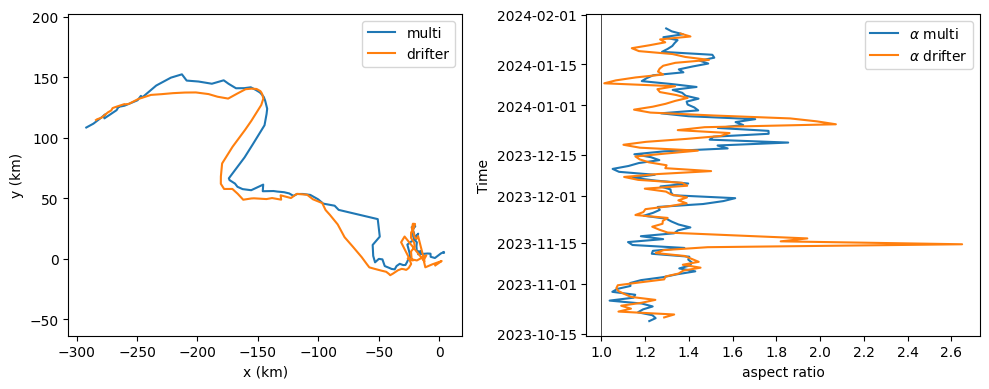

In [6]:
if plot_config["diagnostics"]:
    # quick comparison between multi-paltform and drifter results
    fig, axs = plt.subplots(1, 2, figsize=(10,4), sharey=False)
    axs[0].plot(df_multimodal_res.xc/1e3, df_multimodal_res.yc/1e3, label='multi');
    axs[0].plot(df_drif_res.xc/1e3, df_drif_res.yc/1e3, label='drifter'); axs[0].axis('equal')
    axs[0].set_xlabel('x (km)'); axs[0].set_ylabel('y (km)'); axs[0].legend()

    axs[1].plot(df_multimodal_res.alpha, df_multimodal_res.time, label=r'$\alpha$ multi')
    axs[1].plot(df_drif_res.alpha, df_drif_res.time, label=r'$\alpha$ drifter')
    axs[1].set_xlabel('aspect ratio'); axs[1].set_ylabel('Time')
    axs[1].legend(); axs[1].axvline(1, lw=.5, color='k')
    plt.tight_layout()


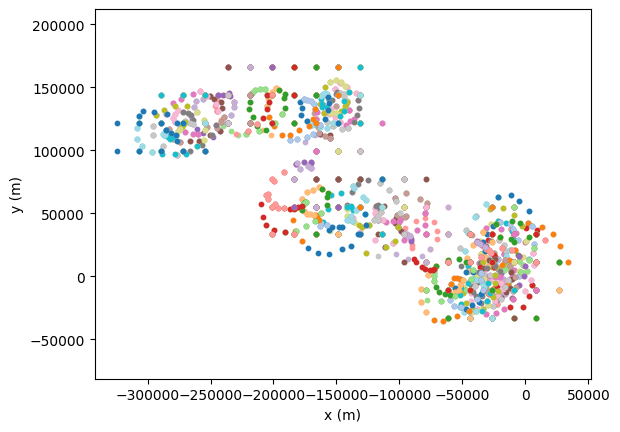

In [7]:
if plot_config["diagnostics"]:
    # Inner-core mutli-platform data used 
    cmap = plt.colormaps['tab20']
    for t, time in enumerate(df_xyuv.time.unique()):
        df = df_xyuv[(df_xyuv.time == time) & (df_xyuv.core == 'inner')]
        plt.scatter(df.xi, df.yi, s=10, color=cmap(t % cmap.N))
    plt.xlabel('x (m)'); plt.ylabel('y (m)')
    plt.axis('equal')


#### Calculate outer-core ESP parameters

,xc,yc,w,Q,Omega,time,alpha,Omega_core,w_core,fit_status,Rc,psi0
0,3658.625906,5330.285689,-0.000032,"[[1.2115938646489601, 0.0540983079752072], [0....",-0.000016,2023-10-19 06:00:00,1.219073,-0.000015,-0.000032,optimized,90058.482133,64533.708788
1,3985.604904,4830.785245,-0.000034,"[[1.235582296488812, 0.07356727634237387], [0....",-0.000017,2023-10-20 06:00:00,1.248043,-0.000016,-0.000032,optimized,87344.876768,63037.912731
2,3489.788395,5262.281371,-0.000034,"[[1.2239955324284832, 0.06314285628023798], [0...",-0.000017,2023-10-21 06:00:00,1.233640,-0.000016,-0.000032,optimized,86800.964744,63519.246765
3,1366.561319,4343.255427,-0.000033,"[[1.1648244596264352, -0.02649719627597246], [...",-0.000016,2023-10-22 06:00:00,1.167104,-0.000014,-0.000029,optimized,88179.966766,62534.033650
4,-3613.979269,538.334076,-0.000032,"[[1.1902034306234104, 0.009181037008192635], [...",-0.000016,2023-10-23 06:00:00,1.190444,-0.000015,-0.000030,optimized,87178.902723,59922.546698
...,...,...,...,...,...,...,...,...,...,...,...,...
96,-276941.047847,116018.477744,-0.000025,"[[0.9003549682383987, -0.2665967224872826], [-...",-0.000012,2024-01-23 06:00:00,1.348285,-0.000013,-0.000026,optimized,78103.300900,36015.594170
97,-277303.233579,118153.726429,-0.000025,"[[0.8612266788375905, -0.1859761295050666], [-...",-0.000012,2024-01-24 06:00:00,1.283250,-0.000013,-0.000026,optimized,77957.405288,36419.436762
98,-276036.683134,119315.200664,-0.000023,"[[0.8309239081483927, -0.2361106209462814], [-...",-0.000011,2024-01-25 06:00:00,1.373348,-0.000012,-0.000024,optimized,79728.718234,35176.084070
99,-286037.248709,111630.770922,-0.000024,"[[0.785813665727795, 0.12541064112915756], [0....",-0.000012,2024-01-26 06:00:00,1.321918,-0.000014,-0.000029,optimized,78522.057891,35576.745480


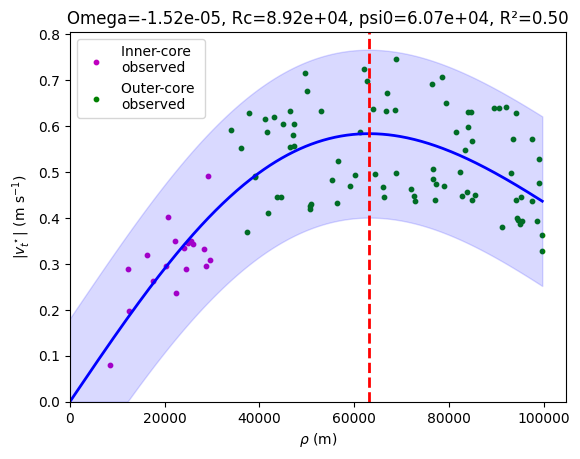

In [8]:
rho_outer = analysis["outer_radius_m"]
dic_outer_mask_data = {}

Rcs, psi0s, Omega_opts = [], [], []
xyuv_rows = []
outer_records = []
outer_count_rows = []

for k in range(len(df_multimodal_res)):
    data = df_multimodal_res.iloc[k]
    time = data.time  # or data.Time if that's your column

    ut = ds_sat.u.sel(time=time).values.ravel()
    vt = ds_sat.v.sel(time=time).values.ravel()

    m = (df_drifters["time"].to_numpy() >= (time - dt)) & (df_drifters["time"].to_numpy() <= (time + dt))
    dfm = df_drifters.iloc[np.flatnonzero(m)]
    xd, yd = dfm["x"].to_numpy(), dfm["y"].to_numpy()
    ud, vd = dfm["u"].to_numpy(), dfm["v"].to_numpy()

    xi = np.concatenate([xd, xg])
    yi = np.concatenate([yd, yg])
    ui = np.concatenate([ud, ut])
    vi = np.concatenate([vd, vt])

    xc, yc, Q, Omega = float(data.xc), float(data.yc), np.asarray(data.Q), float(data.Omega)
    q11, q12, q22 = Q[0,0], Q[0,1], Q[1,1]

    dx = xi - xc
    dy = yi - yc
    rho2 = q11*dx*dx + 2*q12*dx*dy + q22*dy*dy

    outer = rho2 <= rho_outer**2
    xi_o, yi_o, ui_o, vi_o = xi[outer], yi[outer], ui[outer], vi[outer]

    xyuv_rows.append(pd.DataFrame({
        "time": time, "core": "outer",
        "xi": xi_o, "yi": yi_o, "ui": ui_o, "vi": vi_o
    }))

    fit_details = {}
    Rc, psi0, Omega_opt = out_core_param_fit(xi_o, yi_o, ui_o, vi_o, xc, yc, Q, Omega0=Omega, plot=plot_config["diagnostics"] and k == plot_config["diagnostic_step_index"], pred_flag=True, fit_details=fit_details, **outer_fit_kwargs)
    outer_records.append(fit_record(time, fit_details))
    platform_labels = np.concatenate([np.full(len(xd), "drifter"), np.full(len(xg), "sat")])
    candidate_counts = platform_counts(platform_labels, outer, xi, yi, ui, vi)
    used = np.zeros(len(xi), dtype=bool)
    used[np.flatnonzero(outer)[fit_details.get("observation_indices", np.array([], dtype=int))]] = True
    used_counts = platform_counts(platform_labels, used, xi, yi, ui, vi)
    outer_count_rows.append({"time": time,
                             **{"outer_candidates_" + k: v for k, v in candidate_counts.items()},
                             **{"outer_fit_" + k: v for k, v in used_counts.items()}})

    Rcs.append(Rc); psi0s.append(psi0); Omega_opts.append(Omega_opt)

df_xyuv_o = pd.concat(xyuv_rows, ignore_index=True) if xyuv_rows else pd.DataFrame(
    columns=["time","core","xi","yi","ui","vi"]
)

df_xyuv = pd.concat([df_xyuv, df_xyuv_o], ignore_index=True)
df_xyuv = (
    df_xyuv
    .sort_values(by="core", key=lambda s: s.eq("outer"))  # keep inner first
    .drop_duplicates(subset=["time", "xi", "yi", "ui", "vi"], keep="first")
    .reset_index(drop=True)
)

df_multimodal_res["Omega_core"] = df_multimodal_res["Omega"]
df_multimodal_res["w_core"] = df_multimodal_res["w"]
df_multimodal_res["fit_status"] = [record["outer_fit_status"] for record in outer_records]
df_multimodal_res["Rc"] = Rcs
df_multimodal_res["psi0"] = psi0s
df_multimodal_res["Omega"] = Omega_opts
df_multimodal_res["w"] = [Omega*(Q[0,0] + Q[1,1]) for (Omega,Q) in zip(df_multimodal_res.Omega, df_multimodal_res.Q)]
df_multimodal_res


In [9]:
# Find R2
R2_vals = []
for _, row in df_multimodal_res.iterrows():
    df = df_xyuv[df_xyuv.time == row.time]
    xi = df.xi.to_numpy(float)
    yi = df.yi.to_numpy(float)
    u  = df.ui.to_numpy(float)
    v  = df.vi.to_numpy(float)
    uhat, vhat = model_uv_at_xy(xi, yi, row.xc, row.yc, np.asarray(row.Q), row.Omega, row.Rc)
    R2_vals.append(vector_R2(u, v, uhat, vhat))
df_multimodal_res['R2'] = R2_vals
df_multimodal_res


,xc,yc,w,Q,Omega,time,alpha,Omega_core,w_core,fit_status,Rc,psi0,R2
0,3658.625906,5330.285689,-0.000032,"[[1.2115938646489601, 0.0540983079752072], [0....",-0.000016,2023-10-19 06:00:00,1.219073,-0.000015,-0.000032,optimized,90058.482133,64533.708788,0.965772
1,3985.604904,4830.785245,-0.000034,"[[1.235582296488812, 0.07356727634237387], [0....",-0.000017,2023-10-20 06:00:00,1.248043,-0.000016,-0.000032,optimized,87344.876768,63037.912731,0.968198
2,3489.788395,5262.281371,-0.000034,"[[1.2239955324284832, 0.06314285628023798], [0...",-0.000017,2023-10-21 06:00:00,1.233640,-0.000016,-0.000032,optimized,86800.964744,63519.246765,0.968203
3,1366.561319,4343.255427,-0.000033,"[[1.1648244596264352, -0.02649719627597246], [...",-0.000016,2023-10-22 06:00:00,1.167104,-0.000014,-0.000029,optimized,88179.966766,62534.033650,0.962805
4,-3613.979269,538.334076,-0.000032,"[[1.1902034306234104, 0.009181037008192635], [...",-0.000016,2023-10-23 06:00:00,1.190444,-0.000015,-0.000030,optimized,87178.902723,59922.546698,0.935408
...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,-276941.047847,116018.477744,-0.000025,"[[0.9003549682383987, -0.2665967224872826], [-...",-0.000012,2024-01-23 06:00:00,1.348285,-0.000013,-0.000026,optimized,78103.300900,36015.594170,0.767548
97,-277303.233579,118153.726429,-0.000025,"[[0.8612266788375905, -0.1859761295050666], [-...",-0.000012,2024-01-24 06:00:00,1.283250,-0.000013,-0.000026,optimized,77957.405288,36419.436762,0.736041
98,-276036.683134,119315.200664,-0.000023,"[[0.8309239081483927, -0.2361106209462814], [-...",-0.000011,2024-01-25 06:00:00,1.373348,-0.000012,-0.000024,optimized,79728.718234,35176.084070,0.762413
99,-286037.248709,111630.770922,-0.000024,"[[0.785813665727795, 0.12541064112915756], [0....",-0.000012,2024-01-26 06:00:00,1.321918,-0.000014,-0.000029,optimized,78522.057891,35576.745480,0.647260


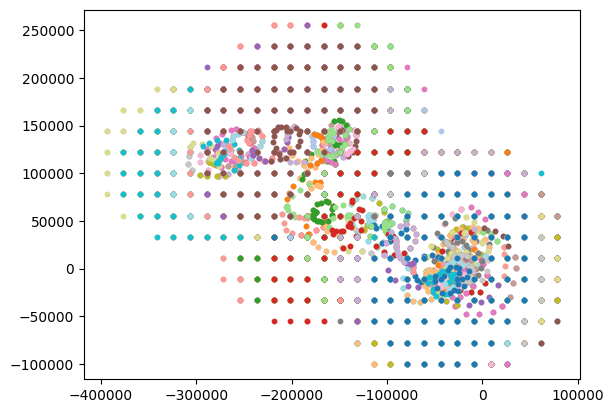

In [10]:
if plot_config["diagnostics"]:
    # Outer-core mutli-platform data used 
    cmap = plt.colormaps['tab20']
    for t, time in enumerate(df_xyuv.time.unique()):
        df = df_xyuv[(df_xyuv.time == time)]
        plt.scatter(df.xi, df.yi, s=10, color=cmap(t % cmap.N))

    plt.axis('equal')


In [11]:
# Reconstruct velocity field using ESP parameters
X = ds_sat.x.values
Y = ds_sat.y.values
nt = len(df_multimodal_res)

U = np.empty((nt, X.shape[0], X.shape[1]))
V = np.empty((nt, X.shape[0], X.shape[1]))

for k in range(nt):
    data = df_multimodal_res.iloc[k]

    dx = X - data.xc
    dy = Y - data.yc

    q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]

    rho2 = q11*dx**2 + 2*q12*dx*dy + q22*dy**2
    fac = data.Omega * np.exp(-rho2 / data.Rc**2)

    U[k] = -fac * (q12*dx + q22*dy)
    V[k] =  fac * (q11*dx + q12*dy)

mask = ds_sat.land_mask.values[None, :, :]   # (1, lat, lon)
U = np.where(mask, np.nan, U)
V = np.where(mask, np.nan, V)

ds_model = xr.Dataset(
    data_vars=dict(
        u=(("time","lat","lon"), U),
        v=(("time","lat","lon"), V),
    ),
    coords=dict(
        time=df_multimodal_res.time.values,
        lat=ds_sat.lat.values,
        lon=ds_sat.lon.values,
        x=(("lat","lon"), X),
        y=(("lat","lon"), Y),
    ),
)


In [12]:
def plot_model(df_res, ds_sat, ds_model, df_xyuv, df_drifters, time=None, spac=1, scale=20,
                xlim=(-410, 200), ylim=(-160, 260), plot_data=False):

    if time is None:
        time = ds_model.time.values[0]

    sat = ds_sat.sel(time=time, method="nearest")
    mod = ds_model.sel(time=time, method="nearest")
    data = df_res[df_res.time == time].iloc[0]
    if not np.isfinite([data.Omega, data.Rc]).all() or data.Rc <= 0:
        print("Gaussian figure unavailable at", time, ":", data.get("fit_status", "invalid outer fit"))
        return

    X = sat.x.values / 1e3
    Y = sat.y.values / 1e3

    us, vs = sat.u.values, sat.v.values
    um, vm = mod.u.values, mod.v.values

    sp_s = np.hypot(us, vs)
    sp_m = np.hypot(um, vm)

    dx = sat.x.values - data.xc
    dy = sat.y.values - data.yc
    q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]
    rho2_grid = q11*dx**2 + 2*q12*dx*dy + q22*dy**2

    roi = (X >= xlim[0]) & (X <= xlim[1]) & (Y >= ylim[0]) & (Y <= ylim[1])
    sp_s_roi = np.where(roi, sp_s, np.nan)
    sp_m_roi = np.where(roi, sp_m, np.nan)
    roi_quiv = roi & (rho2_grid >= analysis["outer_radius_m"]**2)

    vals = np.concatenate([sp_s_roi[roi], sp_m_roi[roi]])
    vmax = np.nanmax(vals)
    levels = np.arange(0, vmax + .05, .05)

    X_rho, Y_rho = np.meshgrid(np.linspace(xlim[0]*1e3, xlim[1]*1e3, 100),
                               np.linspace(ylim[0]*1e3, ylim[1]*1e3, 100))
    dx = X_rho - data.xc
    dy = Y_rho - data.yc
    rho2 = q11*dx**2 + 2*q12*dx*dy + q22*dy**2

    fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True, sharey=True, constrained_layout=True)

    # ----- coloured center path -----
    x_path = df_res.xc.to_numpy() / 1e3
    y_path = df_res.yc.to_numpy() / 1e3
    t_path = pd.to_datetime(df_res.time)
    t_num = mdates.date2num(t_path)

    pts = np.array([x_path, y_path]).T.reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)

    norm_t = Normalize(t_num.min(), t_num.max())
    lc0 = LineCollection(segs, cmap="plasma", norm=norm_t, linewidth=2, zorder=2)
    lc0.set_array(t_num[:-1])

    lc1 = LineCollection(segs, cmap="plasma", norm=norm_t, linewidth=2, zorder=2)
    lc1.set_array(t_num[:-1])

    # ---- Satellite ----
    h0 = axs[0].contourf(X, Y, sp_s_roi, levels=levels, cmap="Blues_r")

    axs[0].quiver(X[::spac,::spac], Y[::spac,::spac],
                  np.where(roi_quiv[::spac,::spac], us[::spac,::spac], np.nan),
                  np.where(roi_quiv[::spac,::spac], vs[::spac,::spac], np.nan),
                  scale=scale, width=.0015, alpha=.4)

    axs[0].scatter(data.xc/1e3, data.yc/1e3, marker="x", color="r", s=50, zorder=3)
    axs[0].add_collection(lc0)
    axs[0].contour(X_rho/1e3, Y_rho/1e3, rho2,
                   levels=[(data.Rc**2)/2], colors="r", linewidths=2,
                   zorder=3, linestyles='--')

    if plot_data:
        df = df_xyuv[(df_xyuv.time == time) & (df_xyuv.core == 'outer')]
        axs[0].quiver(df.xi/1e3, df.yi/1e3, df.ui, df.vi,
                      scale=scale, width=.0025, color='g',
                      label='Outer-core data', zorder=2)
        df = df_xyuv[(df_xyuv.time == time) & (df_xyuv.core == 'inner')]
        axs[0].quiver(df.xi/1e3, df.yi/1e3, df.ui, df.vi,
                      scale=scale, width=.0025, color='m',
                      label='Inner-core data', zorder=2)

    for i, d in enumerate(df_drifters.ID.unique()):
        df = df_drifters[df_drifters.ID == d]
        axs[0].plot(df.x/1e3, df.y/1e3, zorder=1, lw=1, alpha=.5,
                    color='tab:pink' if i == 0 else 'tab:orange')

    axs[0].set_aspect("equal")
    axs[0].legend(loc='lower left')

    # ---- Model ----
    h1 = axs[1].contourf(X, Y, sp_m_roi, levels=levels, cmap="Blues_r")
    axs[1].quiver(X[::spac,::spac], Y[::spac,::spac],
                  np.where(roi[::spac,::spac], um[::spac,::spac], np.nan),
                  np.where(roi[::spac,::spac], vm[::spac,::spac], np.nan),
                  scale=scale, alpha=.5, width=.0015)
    axs[1].scatter(data.xc/1e3, data.yc/1e3, marker="x", color="r", s=50,
                   label='Eddy center', zorder=3)
    axs[1].add_collection(lc1)
    axs[1].contour(X_rho/1e3, Y_rho/1e3, rho2,
                   levels=[(data.Rc**2)/2], colors="r", linewidths=2,
                   zorder=3, linestyles='--')
    axs[1].plot([np.nan, np.nan], [np.nan, np.nan], lw=2, color='r',
                label='Max tangential\nvelocity', ls='--')

    for i, d in enumerate(df_drifters.ID.unique()):
        df = df_drifters[df_drifters.ID == d]
        axs[1].plot(df.x/1e3, df.y/1e3, zorder=1, lw=1, alpha=.5,
                    color='tab:pink' if i == 0 else 'tab:orange',
                    label='Drifter 1' if i == 0 else 'Drifter 2')

    axs[1].set_aspect("equal")
    axs[1].legend(loc='lower left')

    gap = 20
    for ax in axs:
        ax.set_xlim(xlim[0] + gap, xlim[1] - gap)
        ax.set_ylim(ylim[0] + gap, ylim[1] - gap)
        ax.set_xlabel("x (km)")
    axs[0].set_ylabel("y (km)")

    axs[0].text(-0.05, 1.05, "a)", transform=axs[0].transAxes, fontsize=13,
                fontweight="bold", va="top", ha="left")
    axs[1].text(-0.05, 1.05, "b)", transform=axs[1].transAxes, fontsize=13,
                fontweight="bold", va="top", ha="left")

    # speed colourbar
    fig.colorbar(h1, ax=axs, label="Current speed (m s$^{-1}$)", fraction=0.0165, pad=0.02)

    # time colourbar
    cbar2 = fig.colorbar(lc1, ax=axs, fraction=0.0165, pad=0.025)
    cbar2.set_label("Center path time")
    cbar2.ax.yaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))

    plt.show()


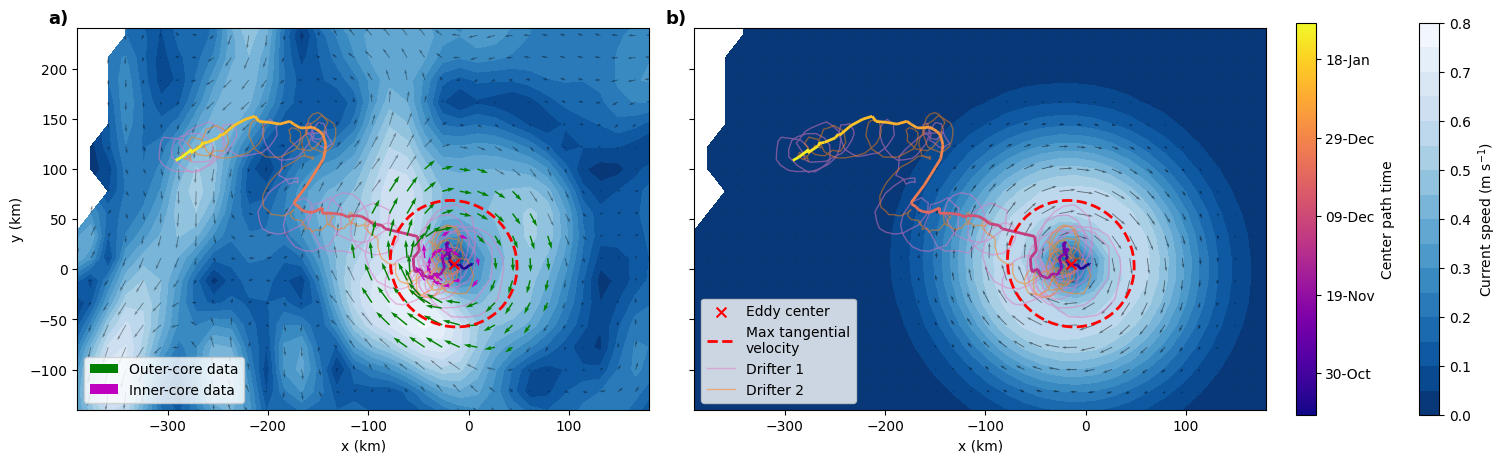

In [13]:
figure_time = select_snapshot_time(df_multimodal_res.time.values, plot_config["snapshot_utc"], plot_config["snapshot_tolerance_hours"])
plot_model(df_multimodal_res, ds_sat, ds_model, df_xyuv, df_drifters, time=figure_time, plot_data=plot_config["plot_data"],
           spac=plot_config["quiver_spacing"], scale=plot_config["quiver_scale"],
           xlim=plot_config["x_limits_km"], ylim=plot_config["y_limits_km"])


In [14]:
# Results
df_paper = df_multimodal_res.copy()
df_paper = df_paper.drop(columns='Q')
df_paper.iloc[::10]


,xc,yc,w,Omega,time,alpha,Omega_core,w_core,fit_status,Rc,psi0,R2
0,3658.625906,5330.285689,-0.000032,-0.000016,2023-10-19 06:00:00,1.219073,-0.000015,-0.000032,optimized,90058.482133,64533.708788,0.965772
10,-14852.249603,5545.961977,-0.000031,-0.000015,2023-10-29 06:00:00,1.049983,-0.000014,-0.000028,optimized,89235.204722,60672.773346,0.928488
20,-21694.797841,25429.628359,-0.000032,-0.000015,2023-11-08 06:00:00,1.413936,-0.000015,-0.000032,optimized,80905.188976,49510.706597,0.936629
30,-24150.376483,702.192603,-0.000030,-0.000014,2023-11-18 06:00:00,1.332534,-0.000015,-0.000032,optimized,93697.764373,62485.517082,0.912391
40,-45105.101895,-6118.830268,-0.000033,-0.000015,2023-11-28 06:00:00,1.464804,-0.000017,-0.000036,optimized,78513.483840,47666.149612,0.832846
50,-95981.750120,45516.545649,-0.000043,-0.000021,2023-12-08 06:00:00,1.244269,-0.000019,-0.000039,optimized,87733.728911,81125.290896,0.774679
60,-145989.186562,55752.439519,-0.000036,-0.000016,2023-12-18 06:00:00,1.531404,-0.000013,-0.000028,optimized,112158.560711,102699.800775,0.867213
70,-144522.891042,110327.628883,-0.000027,-0.000013,2023-12-28 06:00:00,1.398230,-0.000011,-0.000023,optimized,106637.860466,73784.690875,0.741327
80,-168119.997743,140911.634703,-0.000023,-0.000011,2024-01-07 06:00:00,1.435218,-0.000011,-0.000023,optimized,116724.349321,73939.431178,0.803235
90,-246764.337601,134592.312925,-0.000026,-0.000012,2024-01-17 06:00:00,1.516259,-0.000011,-0.000025,optimized,75110.688686,33815.683977,0.738949


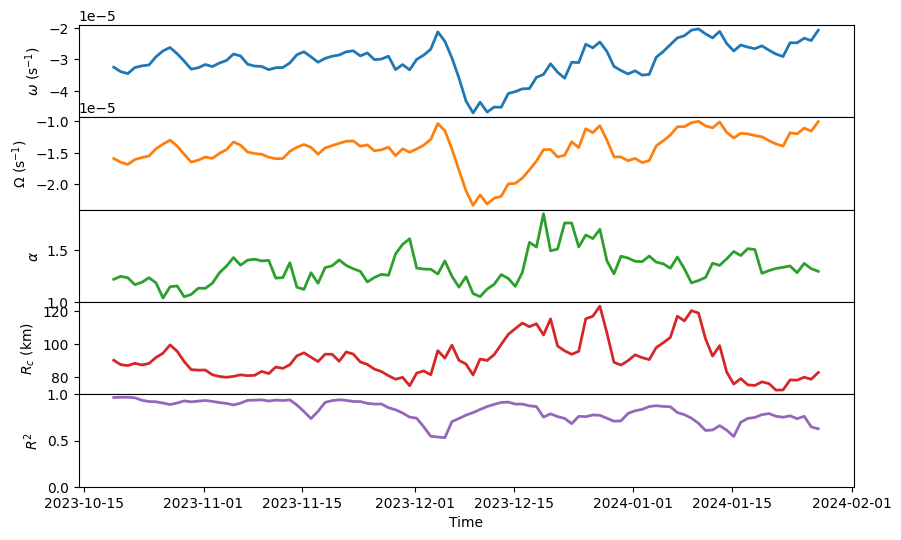

In [15]:
# Time series
clrs = plt.colormaps['tab10']
fig, axs = plt.subplots(5, 1, figsize=(10,6), sharex=True)
lw = 2

axs[0].plot(df_multimodal_res.time, df_multimodal_res.w, color=clrs(0), lw=lw)
axs[0].set_ylabel(r'$\omega$ (s$^{-1}$)')

axs[1].plot(df_multimodal_res.time, df_multimodal_res.Omega, color=clrs(1), lw=lw)
axs[1].set_ylabel(r'$\Omega$ (s$^{-1}$)')

axs[2].plot(df_multimodal_res.time, df_multimodal_res.alpha, color=clrs(2), lw=lw)
axs[2].set_ylabel(r'$\alpha$')
axs[2].set_ylim(1, None)

axs[3].plot(df_multimodal_res.time, df_multimodal_res.Rc/1e3, color=clrs(3), lw=lw)
axs[3].set_ylabel(r'$R_c$ (km)')

axs[4].plot(df_multimodal_res.time, df_multimodal_res.R2, color=clrs(4), lw=lw)
axs[4].set_ylabel(r'$R^2$')
axs[4].set_xlabel('Time')
axs[4].set_ylim(0,1)

fig.subplots_adjust(hspace=0)


### Manuscript results summary
Computed from this run. All dates are UTC; final refined parameters are reported.
This notebook demonstrates ESP on real data; idealised experiments are outside its scope.

In [16]:
with capture_summary() as manuscript_text:
    summary_counts = pd.DataFrame(inner_count_rows).merge(pd.DataFrame(outer_count_rows), on="time", how="outer")
    summary_counts = summary_counts.merge(evaluation_counts(df_xyuv), on="time", how="left")
    print_manuscript_summary(
        "LATTE — drifter and satellite", df_multimodal_res,
        {"Drifter IDs": df_drifters.ID.unique().tolist(),
         "Selected drifter interval": f"{df_drifters.time.min()} to {df_drifters.time.max()} UTC",
         "Drifter observation count": len(df_drifters),
         "Satellite analysis interval": f"{ds_sat.time.values[0]} to {ds_sat.time.values[-1]} UTC",
         "Drifter aggregation half-window": dt,
         "Local origin (longitude, latitude)": (theta_mean, phi_mean),
         "Initial centre (m)": initial_center,
         "Initial/refined core radius (km)": rho_core / 1000,
         "Outer elliptical radius limit (km)": rho_outer / 1000,
         "Maximum step from previous accepted centre (km)": max_center_step / 1000,
         "Accepted rotation sign": rotation_sign,
         "Tracking termination": tracking_stop},
        counts=summary_counts, outer_records=outer_records, snapshot_time=figure_time,
        notes=["Initial selection uses the previous accepted Q; refinement uses the preliminary current-day Q.",
               "The displacement check compares the final centre with the previous accepted day; rejected fits do not advance tracking state.",
               "Velocity R² uses the deduplicated union of inner and outer evaluation rows.",
               "Counts distinguish actual finite drifter and satellite contributions at each stage."],
        input_files=["applications/LATTE_app2_multiplatform_data.ipynb", *config["inputs"].values()], root=REPO_ROOT)
    drifter_counts = pd.DataFrame([{"time": time, "drifter_pairs": int(np.isfinite(samples[["xi", "yi", "ui", "vi"]].to_numpy()).all(axis=1).sum()),
                                   "drifter_ids": samples.ID.nunique()} for time, samples in dic_drif.items()])
    print_manuscript_summary(
        "LATTE — drifter-only inner-core comparison", df_drif_res.assign(source="drifter"),
        {"Drifter aggregation half-window": pd.Timedelta(hours=analysis["aggregation_half_window_hours"]),
         "Outer-core parameters": "not estimated; full-field velocity R² is unavailable"},
        counts=drifter_counts,
        notes=["R2_linear_core is the inner linear-flow fit; it is not the Gaussian reconstruction R².",
               "Rc, psi0 and R2_velocity are unavailable for the drifter-only comparison."], root=REPO_ROOT)

export_directory = export_application_results(
    REPO_ROOT, CONFIG_PATH, config,
    pd.concat([df_multimodal_res.assign(source="multi"), df_drif_res.assign(source="drifter")], ignore_index=True), manuscript_text.getvalue(),
    notebook="applications/LATTE_app2_multiplatform_data.ipynb",
    tables={"observation_counts": summary_counts, "outer_fit_diagnostics": pd.DataFrame(outer_records), "drifter_counts": drifter_counts},
    run_info={"snapshot_time_utc": figure_time, "tracking_stop": tracking_stop})



MANUSCRIPT RESULTS SUMMARY — LATTE — drifter and satellite
Current run; compare with the manuscript after any analysis change. All times UTC.

DATA AND SETTINGS
  Drifter IDs: [300534062034380, 300534062784620]
  Selected drifter interval: 2023-10-19 12:00:00 to 2024-01-27 06:00:00 UTC
  Drifter observation count: 787
  Satellite analysis interval: 2023-10-19T06:00:00.000000000 to 2024-01-27T06:00:00.000000000 UTC
  Drifter aggregation half-window: 1 days 00:00:00
  Local origin (longitude, latitude): (154.3, -37.9)
  Initial centre (m): (0.0, 0.0)
  Initial/refined core radius (km): 35.0
  Outer elliptical radius limit (km): 100.0
  Maximum step from previous accepted centre (km): 100.0
  Accepted rotation sign: -1.0
  Tracking termination: input record exhausted

PLOTTED SNAPSHOT: 2023-10-29T06:00:00.000000000 UTC

MANUSCRIPT-ROUNDED VALUES (final refined Omega; omega = Omega tr(Q))
  combined, 2023-10-29 06:00:00 UTC: (x0,y0)=(-14.9, 5.5) km; omega=-3.1e-05 s^-1; Omega=-1.5e-05 s^-